# Classificação do crescimento do PIB — Amanda

Regressão Logística multiclasse. Execute todas as células. O código reutiliza o pré-processamento de Peter e salva os resultados em `outputs/`.

## Classes e limites
Variação = 100 × (PIB do ano / PIB anterior − 1).

- Forte retração: abaixo de −5%.
- Retração: de −5% (inclusivo) até −1% (exclusivo).
- Estabilidade: de −1% a 1%, inclusive.
- Crescimento moderado: acima de 1% até 5%, inclusive.
- Forte crescimento: acima de 5%.

O alvo usa a variação do próprio ano; ele nunca entra nas variáveis explicativas. Treino até 2022, teste em 2023 e reajuste até 2023 para prever 2024. As entradas usam anos anteriores. O exercício é retrospectivo por ano de referência, sem garantir que os dados já estivessem publicados na data do corte.

In [1]:
from pathlib import Path
import sys
raiz = Path.cwd()
if raiz.name == 'notebooks':
    raiz = raiz.parent
sys.path.insert(0, str(raiz))
from classificacao_logistica import executar, CLASSES
metricas, matriz, previsoes = executar()
metricas

/private/tmp/uv-amanda/archive-v0/IAZLIsu6eYSRsgKK/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/private/tmp/uv-amanda/archive-v0/IAZLIsu6eYSRsgKK/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/private/tmp/uv-amanda/archive-v0/IAZLIsu6eYSRsgKK/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/private/tmp/uv-amanda/archive-v0/IAZLIsu6eYSRsgKK/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:336: RuntimeWarning: divide by zero encountered in matmul
  grad[:, :n_features] = grad_pointwise.T @ X + l2_reg_strength * weights
/priva

 ano               classe  precision   recall  f1-score  support
2023       forte retração   0.190698 0.752294  0.304267    109.0
2023             retração   0.035928 0.092308  0.051724     65.0
2023         estabilidade   0.014085 0.023810  0.017699     42.0
2023 crescimento moderado   0.137615 0.120000  0.128205    125.0
2023    forte crescimento   0.890011 0.597589  0.715059   1327.0
2023            macro avg   0.253667 0.317200  0.243391   1668.0
2023         weighted avg   0.732590 0.537770  0.600827   1668.0
Previsões 2024: 1668 municípios


/private/tmp/uv-amanda/archive-v0/IAZLIsu6eYSRsgKK/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/private/tmp/uv-amanda/archive-v0/IAZLIsu6eYSRsgKK/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/private/tmp/uv-amanda/archive-v0/IAZLIsu6eYSRsgKK/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/private/tmp/uv-amanda/archive-v0/IAZLIsu6eYSRsgKK/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:336: RuntimeWarning: divide by zero encountered in matmul
  grad[:, :n_features] = grad_pointwise.T @ X + l2_reg_strength * weights
/priva

,ano,classe,precision,recall,f1-score,support
0,2023,forte retração,0.190698,0.752294,0.304267,109.0
1,2023,retração,0.035928,0.092308,0.051724,65.0
2,2023,estabilidade,0.014085,0.023810,0.017699,42.0
3,2023,crescimento moderado,0.137615,0.120000,0.128205,125.0
4,2023,forte crescimento,0.890011,0.597589,0.715059,1327.0
5,2023,macro avg,0.253667,0.317200,0.243391,1668.0
6,2023,weighted avg,0.732590,0.537770,0.600827,1668.0


## Matriz de confusão de 2023
Linhas representam classes reais; colunas, classes previstas. O F1 macro dá o mesmo peso às cinco classes e é a métrica principal. O F1 ponderado considera a frequência das classes. Os pesos balanceados no treino ajudam a tratar o desequilíbrio sem ajustar parâmetros usando o teste.

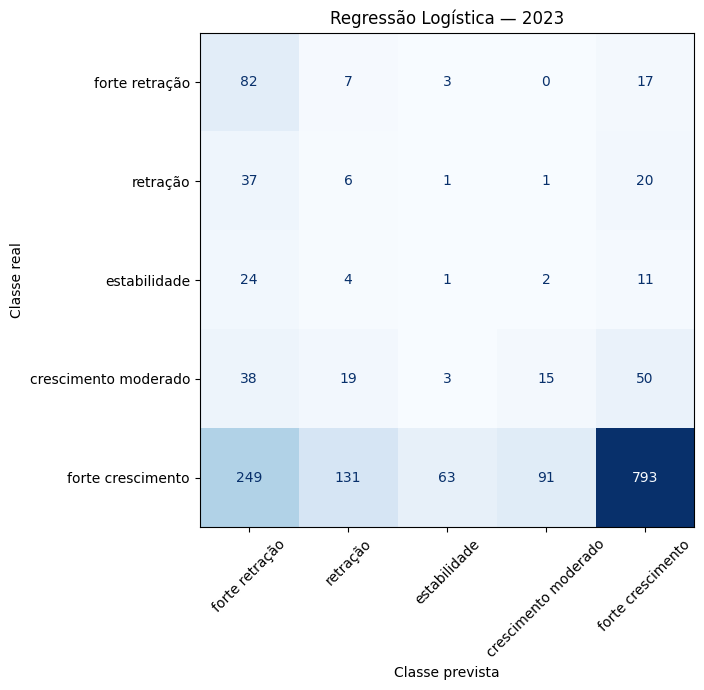

In [2]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(matriz.to_numpy(), display_labels=CLASSES).plot(ax=ax, cmap='Blues', colorbar=False, xticks_rotation=45)
ax.set_xlabel('Classe prevista')
ax.set_ylabel('Classe real')
ax.set_title('Regressão Logística — 2023')
fig.tight_layout()
plt.show()

In [3]:
previsoes.groupby('classe_prevista').size().reindex(CLASSES, fill_value=0)

classe_prevista
forte retração            42
retração                   0
estabilidade               0
crescimento moderado       0
forte crescimento       1626
dtype: int64

## Análise e integração
A interpretação dos resultados está em `docs/contribuicao_classificacao_logistica.md`. A matriz e as previsões individuais de 2023 permitem revisar acertos e erros. A comparação com Random Forest Classifier deve usar os mesmos municípios, limites e corte temporal, priorizando F1 macro. Não há resultado desse classificador ainda neste repositório.

As categorias de 2024 são previsões, não resultados oficiais. O PIB nominal inclui inflação; a regressão logística tem fronteiras lineares e pode não capturar choques locais. Classes próximas aos limites são sensíveis a pequenas diferenças no PIB.